In [1]:
import pandas as pd

df = pd.read_csv('D:\FYP\Code\Dataset\downsampled_data.csv')

# Data Preprocessing

Using multiple antennas is an effective method to improve the detection performance, which will lead to a higher computation complex. Consequently, data fusion is the first step in feature extraction. <br>
The __median amplitudes__ of CSI are chosen as the final amplitudes, which are from the subcarriers of the same frequency.

In [2]:
import numpy as np

# Amplitude data only.
X1 = df.iloc[:, 2:66]
X2 = df.iloc[:, 130:194]

# Ensure X1 and X2 have the same shape
assert X1.shape == X2.shape, "X1 and X2 must have the same shape"

# Initialize X with the same shape as X1 and X2
X = pd.DataFrame(index=X1.index, columns=X1.columns)

# Compute the median for each cell
for i in range(X1.shape[0]):
    for j in range(X1.shape[1]):
        X.iloc[i, j] = np.median([X1.iloc[i, j], X2.iloc[i, j]])

Y = df.iloc[:, -1]

In [3]:
X

,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,amplitude10_1,...,amplitude55_1,amplitude56_1,amplitude57_1,amplitude58_1,amplitude59_1,amplitude60_1_1,amplitude61_1,amplitude62_1,amplitude63_1,amplitude64_1
0,60.433343,3.285398,13.466784,14.581471,15.234641,15.200463,14.813292,14.144137,13.319824,12.256932,...,15.079544,14.851077,14.635254,13.316219,12.200099,11.281152,10.169046,9.181208,9.078126,9.25099
1,60.433343,3.285398,13.196697,13.892851,14.457289,14.404498,13.778776,13.433429,12.546016,11.297553,...,14.206272,14.214602,13.740455,12.788558,11.794453,10.747192,10.203248,9.252031,9.162335,9.505313
2,60.433343,3.285398,15.797192,16.482393,17.436565,17.599576,17.090032,16.734446,15.440602,14.164159,...,17.371619,17.221309,16.602563,15.991866,14.902211,13.443891,12.325225,11.612877,11.138468,11.434321
3,60.433343,3.285398,14.5,15.5,16.062429,16.186693,16.00129,15.332687,14.315715,13.211565,...,15.942399,15.58798,14.904892,14.198631,13.167997,12.080463,10.989561,10.411381,10.05797,10.430253
4,60.433343,3.285398,15.093779,16.073704,16.477459,16.847736,16.777589,15.851979,14.998482,13.758131,...,17.169487,16.745231,16.200203,15.501605,14.398135,13.000446,11.763092,11.086122,10.971717,11.285398
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116570,60.433343,3.285398,2.715507,3.929919,4.775344,5.896787,7.017287,7.469623,7.740521,7.740521,...,7.413327,8.364618,8.844232,9.205297,9.11021,8.616579,8.046736,7.053364,5.567751,4.582541
116571,60.433343,3.285398,5.911997,8.42132,11.297767,13.348098,14.907263,15.978107,16.186241,16.311447,...,15.228776,17.219449,18.120368,18.613754,18.8757,18.037566,16.518982,14.312827,11.932114,9.434975
116572,60.433343,3.285398,6.017169,8.398126,11.383138,13.438757,15.02079,15.65712,16.481995,16.43405,...,15.446083,17.244979,18.186482,18.73235,18.91745,18.137478,17.050482,14.935105,12.511919,10.127403
116573,60.433343,3.285398,6.607392,8.909833,11.819468,13.814231,15.311251,16.349836,16.972091,17.057031,...,13.933095,15.696596,16.553266,16.992051,17.473823,16.615685,15.502048,13.699174,10.52373,8.487174


In [4]:
Y

0         4
1         4
2         4
3         4
4         4
         ..
116570    0
116571    0
116572    0
116573    0
116574    0
Name: activity, Length: 116575, dtype: int64

Save the data to a CSV file to get rid of the data preprocessing step in the future.

In [13]:
# Concatenate X and Y
data = pd.concat([X, Y], axis=1)

# Save the data to a CSV file
data.to_csv('median_amplitudes1.csv', index=False)

In [14]:
import pandas as pd

# Read from the the data to a CSV file to get rid of the data preprocessing step in the future.
data = pd.read_csv('median_amplitudes1.csv')
X = data.iloc[:, :-1]
Y = data.iloc[:, -1]

## Label Mapping for Night and Day time


### Night Time

In [15]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0	# Static environment
	elif prediction == 5:
		return 1	# Wake Up
	else:
		return 2	# Intrusion

In [10]:
np.unique(Y)

array([0, 1, 2, 3, 4, 5], dtype=int64)

In [11]:
Y.head()

0    0
1    0
2    0
3    0
4    0
Name: activity, dtype: int64

In [16]:
Y_night = Y.copy()

for i in range (len(Y)):
	Y_night[i] = predictionMapping(Y[i])

In [17]:
np.unique(Y_night)

array([0, 1, 2], dtype=int64)

In [19]:
Y_night

0         0
1         0
2         0
3         0
4         0
         ..
116570    0
116571    0
116572    0
116573    0
116574    0
Name: activity, Length: 116575, dtype: int64

# Feature extraction

In [37]:
sample_rate = 25  # Hz
window = 3    # Window size in seconds
window_size = window * sample_rate

num_subcarriers = 64

In [38]:
import numpy as np

features = []
labels = []

for window_start in range(0, len(X) - window_size + 1 , window_size):
    window_end = window_start + window_size
    window_data = X.iloc[window_start:window_end]
    
    # Calculate the variance of the amplitudes of each subcarrier within the sliding window
    V_w = np.var(window_data, axis=0)
    # Calculate the variance of all subcarriers' variances
    V = np.var(V_w)
    features.append([V])

    labels.append(Y_night.iloc[window_end - 1])   # Assuming the label for the window is the label of the last sample in the window

In [23]:
features = pd.DataFrame(features, columns=['V'])

In [24]:
features

,V
0,0.899126
1,0.678474
2,0.899741
3,0.357620
4,0.149402
...,...
4658,34.246727
4659,31.423259
4660,31.311769
4661,40.814214


In [25]:
Y.shape[0]//25

4663

In [39]:
len(labels)

1554

Convert features and labels to DataFrame

In [40]:
features_df = pd.DataFrame(features)
labels_df = pd.Series(labels)

# Classification Model

Split the data into training and validation sets

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(features_df, labels_df, test_size=0.2, random_state=42)

In [42]:
from hmmlearn import hmm

# Train HMM
n_components = len(np.unique(labels)) # Hidden states: No. of activity patterns

# ML MODEL
model = hmm.GaussianHMM(n_components=n_components, covariance_type="full", n_iter=1000)

# Fit the model on the training data
model.fit(X_train)


GaussianHMM(covariance_type='full', n_components=3, n_iter=1000)

In [43]:
# Decode the sequence of hidden states on validation data using Viterbi algorithm
logprob, hidden_states = model.decode(X_val.values, algorithm="viterbi")

In [44]:
# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

# Assuming binary classification: 1 for moving, 0 for static
accuracy = accuracy_score(y_val, hidden_states)
report = classification_report(y_val, hidden_states, zero_division=0)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)


Accuracy: 0.43086816720257237
Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.57      0.64       167
           1       0.01      0.07      0.01        15
           2       0.81      0.29      0.43       129

    accuracy                           0.43       311
   macro avg       0.51      0.31      0.36       311
weighted avg       0.73      0.43      0.52       311



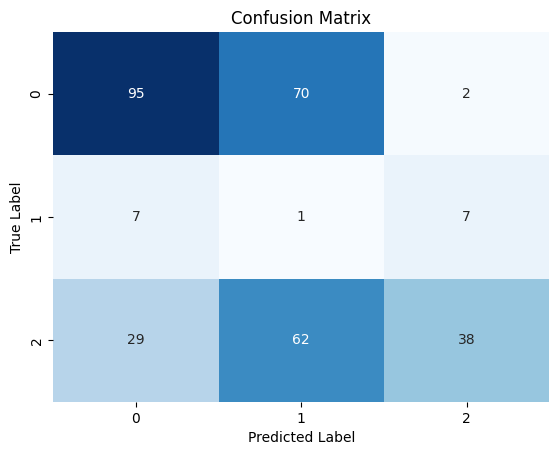

In [45]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, hidden_states)

# Plot the confusion matrix using seaborn heatmap
plt.figure()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()